# Pretrained Model VGG16 for Feature Extraction

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.layers import (
    Input, Dense, Dropout, GlobalAveragePooling2D, RandomRotation
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

C:\Users\Thidar Khaing\.conda\envs\deepenv\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [3]:
dataset_dir = "D:/Deep Learning for Image/dataset"

img_height = 224
img_width = 224
batch_size = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.30,
    subset="training",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="categorical"
)

temp_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.30,
    subset="validation",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="categorical"
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)

Found 1181 files belonging to 5 classes.
Using 827 files for training.
Found 1181 files belonging to 5 classes.
Using 354 files for validation.
Classes: ['bike', 'dogs', 'flowers', 'horses', 'human']
Number of classes: 5


In [4]:
# 15% validation and 15% testing
val_batches = tf.data.experimental.cardinality(temp_ds)

test_ds = temp_ds.take(val_batches // 2)
val_ds = temp_ds.skip(val_batches // 2)

class_names = train_ds.class_names

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Classes: ['bike', 'dogs', 'flowers', 'horses', 'human']
Number of classes: 5


In [5]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

val_ds = val_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

test_ds = test_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

# Improve loading performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

In [6]:
data_augmentation = tf.keras.Sequential([

    # Random rotation (±10%)
    RandomRotation(0.1),

    # Random horizontal flipping
    #RandomFlip("horizontal"),

    # Random brightness changes
    #RandomBrightness(factor=0.2),

])

In [7]:
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
) 

In [8]:
base_model.trainable = False

In [9]:
inputs = Input(shape=(224, 224, 3))

# Data augmentation
x = data_augmentation(inputs)

# VGG16 preprocessing
#x = preprocess_input(x)

# Extract features using pretrained VGG16
x = base_model(x, training=False)

# Convert feature maps into a feature vector
x = GlobalAveragePooling2D()(x)

# Fully connected layer
x = Dense(256, activation="relu")(x)

# Dropout
x = Dropout(0.5)(x)

# Classification layer
outputs = Dense(num_classes, activation="softmax")(x)

# Create model
model = Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ sequential (Sequential)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 7, 7, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 5)                   │           1,285 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,847,301 (56.64 MB)

 Trainable params: 132,613 (518.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [10]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [12]:
epochs = 5

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)

Epoch 1/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 150s 6s/step - accuracy: 0.8597 - loss: 0.4818 - val_accuracy: 0.9321 - val_loss: 0.3530
Epoch 2/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 146s 6s/step - accuracy: 0.8815 - loss: 0.4035 - val_accuracy: 0.9321 - val_loss: 0.2700
Epoch 3/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 148s 6s/step - accuracy: 0.8839 - loss: 0.3601 - val_accuracy: 0.9630 - val_loss: 0.1955
Epoch 4/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 149s 6s/step - accuracy: 0.9117 - loss: 0.3133 - val_accuracy: 0.9321 - val_loss: 0.2559
Epoch 5/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 147s 6s/step - accuracy: 0.8984 - loss: 0.3044 - val_accuracy: 0.9198 - val_loss: 0.2401


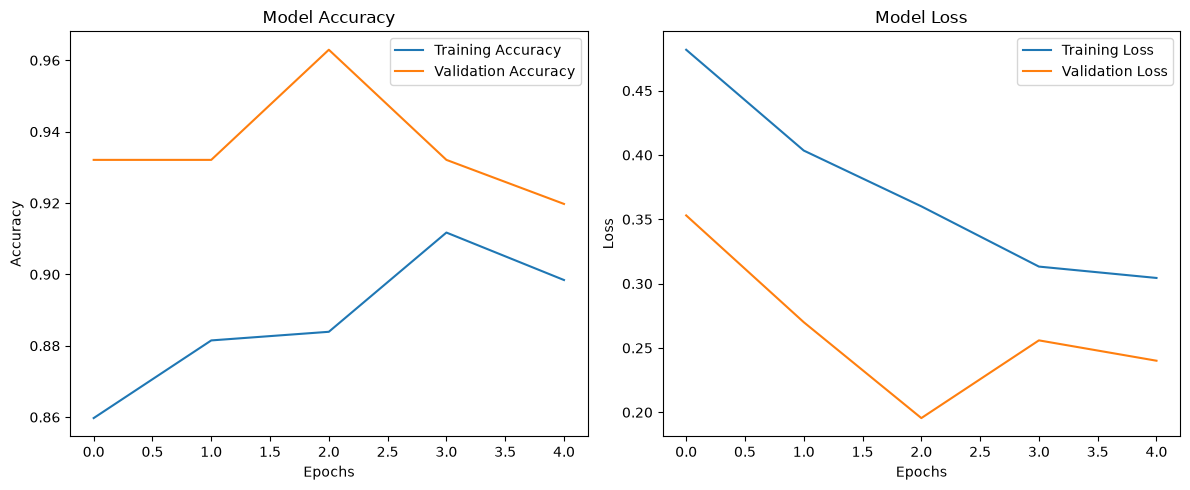

In [13]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

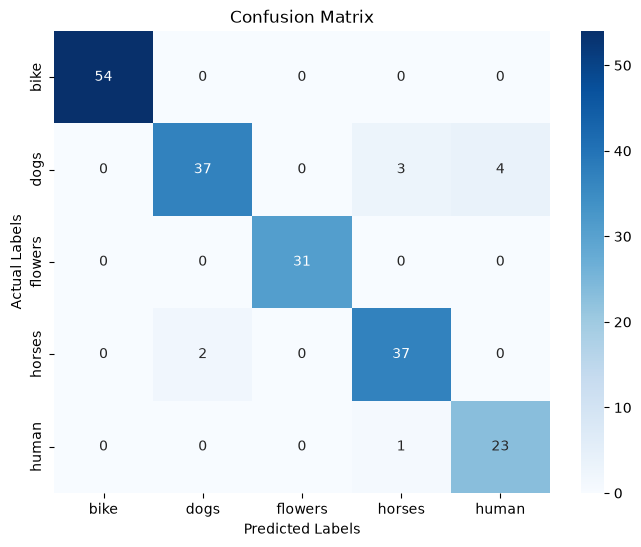

In [14]:
y_true = []
y_pred = []

for images, labels in test_ds:

    # Actual labels
    y_true.extend(np.argmax(labels.numpy(), axis=1))

    # Predicted labels
    predictions = model.predict(images, verbose=0)

    y_pred.extend(np.argmax(predictions, axis=1))

# Convert to NumPy arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Labels')
plt.ylabel('Actual Labels')
plt.title('Confusion Matrix')

plt.show()

In [15]:
# Classification Report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

        bike       1.00      1.00      1.00        54
        dogs       0.95      0.84      0.89        44
     flowers       1.00      1.00      1.00        31
      horses       0.90      0.95      0.93        39
       human       0.85      0.96      0.90        24

    accuracy                           0.95       192
   macro avg       0.94      0.95      0.94       192
weighted avg       0.95      0.95      0.95       192



In [16]:
model.save("D:/Deep Learning for Image/models/vgg16_feature_extraction_model.keras")

In [18]:
from tensorflow.keras.models import load_model
# Load trained model
model = load_model(
    "D:/Deep Learning for Image/models/vgg16_feature_extraction_model.keras"
)

# Class names (must follow training dataset order)
class_names = ['bike', 'dogs', 'flowers', 'horses', 'human']

# Image path
image_path = "D:/Deep Learning for Image/Test_Images/test.jpg"

# Load and resize image
img = tf.keras.utils.load_img(
    image_path,
    target_size=(224, 224)
)

# Convert image to array
img_array = tf.keras.utils.img_to_array(img)

# Normalize pixel values
img_array = img_array / 255.0

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array)

# Get predicted class
predicted_index = np.argmax(prediction[0])

predicted_class = class_names[predicted_index]

confidence = prediction[0][predicted_index] * 100

print("Predicted Class:", predicted_class)
print("Confidence: {:.2f}%".format(confidence))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 906ms/step
Predicted Class: human
Confidence: 97.75%
